# From Global Depletion to Locked Enstrophy

### Reproduction notebook

**Dean Kulik** · QuHarmonics Research Group · ORCID 0009-0003-3128-8828

This notebook reproduces every numerical result in the paper *From Global Depletion to Locked
Enstrophy: a retraction, a change of variable, and two confounds in the vorticity-alignment
reading of three-dimensional Navier–Stokes*.

| section | reproduces | runtime |
|---|---|---|
| 1 | the pseudospectral engine | — |
| 2 | conservation and regression suite (12 checks) | ~30 s |
| 3 | Tables 1–2, reproduction of the July 2026 Taylor–Green run | ~20 s / ~2 min |
| 4 | Table 3, the blindness of the global depletion ratio | instant |
| 5 | Table 4, the Reynolds sweep with resolution verdicts | ~2–8 min |
| 6 | Table 5 and Figure 1, threshold dependence of the exponent | ~3 min |
| 7 | Table 6, pressure nonlocality | ~10 s |

Set `QUICK = True` below to skip the two expensive grids (96³ and 112³). The scientific
conclusions of sections 4, 6 and 7 are unaffected; the resolution comparison in section 5
requires `QUICK = False`.

Requires only NumPy and Matplotlib. Double precision throughout. Single-threaded.

In [1]:
QUICK = True          # True: skip 96^3 and 112^3 runs (~3 min total).  False: everything (~9 min).

import numpy as np, math, time
import matplotlib.pyplot as plt
print("numpy", np.__version__)

numpy 2.4.3


---
## 1. The engine

Pseudospectral, triply periodic box of side $2\pi$, Taylor–Green initial condition

$$u = \sin x\,\cos y\,\cos z,\qquad v = -\cos x\,\sin y\,\cos z,\qquad w = 0.$$

The velocity is advanced in rotational form so the nonlinear term is evaluated as
$\mathbf{u}\times\boldsymbol\omega$ and pressure is eliminated by projection onto the
divergence-free subspace. Aliasing is removed by the two-thirds rule. The viscous operator is
treated exactly by an integrating factor, so the step is limited only by the advective Courant
condition. Time integration is second-order Runge–Kutta in the integrating-factor variable.

Two diagnostics matter. The **depletion ratio**

$$D = \frac{\langle \boldsymbol\omega\cdot S\boldsymbol\omega\rangle}{\langle\lambda_1|\boldsymbol\omega|^2\rangle}$$

is the fraction of available stretching the flow takes up. The **locked-enstrophy fraction**

$$L(\theta) = \frac{\int |\boldsymbol\omega|^2\,\mathbf{1}\!\left[\,|\cos(\boldsymbol\omega, e_1)| > \theta\,\right]}{\int |\boldsymbol\omega|^2}$$

is the share of enstrophy sitting within $\arccos\theta$ of the most-stretching strain
eigenvector. The engine accumulates $L$ at seven cutoffs; `locked` is the inherited $\theta = 0.9$.

Note on the dissipation term: `irfftn` returns a **real** array, so `f**2` is `|f|**2`. Sections 2
and the energy budget test this directly.

In [2]:
import numpy as np, time, json, sys

def run(N, Re, T=10.0, cfl=0.4, nsamp=11, verbose=False):
    nu=1.0/Re
    k1=np.fft.fftfreq(N,1.0/N)
    kz=np.fft.rfftfreq(N,1.0/N)
    KX,KY,KZ=np.meshgrid(k1,k1,kz,indexing='ij')
    K2=KX**2+KY**2+KZ**2; K2i=1.0/np.where(K2==0,1,K2); K2i[0,0,0]=0
    kmax=N//3
    mask=(np.abs(KX)<kmax)&(np.abs(KY)<kmax)&(np.abs(KZ)<kmax)
    x=np.linspace(0,2*np.pi,N,endpoint=False)
    X,Y,Z=np.meshgrid(x,x,x,indexing='ij')
    u=np.sin(X)*np.cos(Y)*np.cos(Z)
    v=-np.cos(X)*np.sin(Y)*np.cos(Z)
    w=np.zeros_like(u)
    AX=(0,1,2)
    F=lambda f: np.fft.rfftn(f,axes=AX); Fi=lambda f: np.fft.irfftn(f,s=(N,N,N),axes=AX)
    U=[F(u),F(v),F(w)]
    def project(A):
        div=KX*A[0]+KY*A[1]+KZ*A[2]
        return [A[0]-KX*div*K2i, A[1]-KY*div*K2i, A[2]-KZ*div*K2i]
    U=project(U)
    def curlF(A):
        return [1j*(KY*A[2]-KZ*A[1]), 1j*(KZ*A[0]-KX*A[2]), 1j*(KX*A[1]-KY*A[0])]
    def nonlin(A):
        ua=[Fi(a) for a in A]; W=curlF(A); wa=[Fi(a) for a in W]
        cx=ua[1]*wa[2]-ua[2]*wa[1]
        cy=ua[2]*wa[0]-ua[0]*wa[2]
        cz=ua[0]*wa[1]-ua[1]*wa[0]
        C=[F(cx)*mask,F(cy)*mask,F(cz)*mask]
        return project(C), ua, wa
    def diag(A):
        ua=[Fi(a) for a in A]; W=curlF(A); wa=[Fi(a) for a in W]
        G=np.empty((N,N,N,3,3))
        for i in range(3):
            for j in range(3):
                G[...,i,j]=Fi(1j*[KX,KY,KZ][j]*A[i])
        S=0.5*(G+np.swapaxes(G,-1,-2))
        lam,vec=np.linalg.eigh(S)          # ascending
        l3,l2,l1=lam[...,0],lam[...,1],lam[...,2]
        e3,e2,e1=vec[...,0],vec[...,1],vec[...,2]
        om=np.stack(wa,axis=-1); w2=np.sum(om**2,axis=-1)
        nrm=np.sqrt(np.maximum(w2,1e-30))
        c1=np.abs(np.sum(om*e1,axis=-1))/nrm
        c2=np.abs(np.sum(om*e2,axis=-1))/nrm
        c3=np.abs(np.sum(om*e3,axis=-1))/nrm
        Sw=np.einsum('...ij,...j->...i',S,om)
        prod=np.sum(om*Sw,axis=-1)
        P=prod.mean(); Plock=(l1*w2).mean()
        ens=0.5*w2.mean()
        # exhaust: nu * <|grad omega|^2>.  irfftn returns a real field, so f**2 is |f|**2.
        exh=0.0
        for a in wa:
            Wa=F(a)
            g=Fi(1j*KX*Wa)**2+Fi(1j*KY*Wa)**2+Fi(1j*KZ*Wa)**2
            exh+=g.mean()
        exh*=nu
        locked=(w2*(c1>0.9)).sum()/w2.sum()
        Lthr={f'L{int(th*100)}':float((w2*(c1>th)).sum()/w2.sum()) for th in (0.70,0.75,0.80,0.85,0.90,0.95,0.98)}
        ke=0.5*sum((q**2).mean() for q in ua)
        divmax=float(np.abs(Fi(1j*(KX*A[0]+KY*A[1]+KZ*A[2]))).max())
        eps=nu*w2.mean()
        eta=(nu**3/max(eps,1e-30))**0.25
        return dict(**Lthr,ens=float(ens),ke=float(ke),div=divmax,P=float(P),Plock=float(Plock),
                    D=float(P/Plock) if Plock>0 else 0.0,
                    EXH=float(exh), PEXH=float(P/exh) if exh>0 else 0.0,
                    c1=float((w2*c1).sum()/w2.sum()),
                    c2=float((w2*c2).sum()/w2.sum()),
                    c3=float((w2*c3).sum()/w2.sum()),
                    locked=float(locked), trS=float(np.abs(np.trace(S,axis1=-2,axis2=-1)).max()),
                    kmax_eta=float(kmax*eta), eps=float(eps))
    samples=np.linspace(0,T,nsamp); si=0; out=[]
    t=0.0; t0=time.time()
    while t<T-1e-12:
        ua=[Fi(a) for a in U]
        umax=max(np.abs(a).max() for a in ua)
        dt=min(cfl*(2*np.pi/N)/max(umax,1e-9), 0.05, T-t)
        if si<nsamp and t>=samples[si]-1e-9:
            d=diag(U); d['t']=t; out.append(d); si+=1
            if verbose: print(f"  t={t:5.2f} ens={d['ens']:.4f} D={d['D']:.4f} lock={d['locked']:.4f} kmax*eta={d['kmax_eta']:.2f}",flush=True)
        IF=np.exp(-nu*K2*dt)              # exact viscous integrating factor
        Nl,_,_=nonlin(U)
        U1=[IF*(U[i]+dt*Nl[i]) for i in range(3)]
        Nl1,_,_=nonlin(U1)
        U=[IF*(U[i]+0.5*dt*Nl[i])+0.5*dt*Nl1[i] for i in range(3)]
        t+=dt
    d=diag(U); d['t']=t; out.append(d)
    if verbose: print(f"  t={t:5.2f} ens={d['ens']:.4f} D={d['D']:.4f} lock={d['locked']:.4f}",flush=True)
    return out, time.time()-t0

---
## 2. Validation

Two independent conservation laws. The enstrophy budget

$$\tfrac12\frac{d}{dt}\langle|\boldsymbol\omega|^2\rangle = \underbrace{\langle\boldsymbol\omega\cdot S\boldsymbol\omega\rangle}_{P} - \underbrace{\nu\langle|\nabla\boldsymbol\omega|^2\rangle}_{E}$$

involves the strain eigendecomposition and the production term. The energy budget

$$\frac{dK}{dt} = -2\nu\,\Omega$$

involves neither. A misformed dissipation or production term cannot satisfy both to
sub-percent accuracy, which is a stronger check on the implementation than reading the code.

In [3]:
FAIL = []
def check(name, value, limit, fmt="{:.3e}"):
    ok = value <= limit
    print(f"  [{'PASS' if ok else 'FAIL'}]  {name:<50s} {fmt.format(value):>12s}  (limit {fmt.format(limit)})")
    if not ok: FAIL.append(name)

t0 = time.time()
val, _ = run(64, 400, T=10.0, nsamp=41)
t   = np.array([d['t']   for d in val]);  ens = np.array([d['ens'] for d in val])
P   = np.array([d['P']   for d in val]);  E   = np.array([d['EXH'] for d in val])
ke  = np.array([d['ke']  for d in val]);  nu  = 1.0/400
m   = (t > 2) & (t < 9.5)

print("1. Incompressibility")
check("max pointwise |div u|", max(d['div']  for d in val), 1e-10)
check("max |tr S|",            max(d['trS']  for d in val), 1e-12)

print("\n2. Enstrophy budget   dOmega/dt = P - E")
rel = np.abs(np.gradient(ens, t) - (P - E))[m] / np.maximum(np.abs(P), np.abs(E))[m]
check("mean relative residual, 2 < t < 9.5", float(rel.mean()), 0.01, "{:.4f}")
check("max  relative residual, 2 < t < 9.5", float(rel.max()),  0.05, "{:.4f}")

print("\n3. Energy budget   dK/dt = -2*nu*Omega   (independent)")
relk = np.abs(np.gradient(ke, t) + 2*nu*ens)[m] / (2*nu*ens)[m]
check("mean relative residual, 2 < t < 9.5", float(relk.mean()), 0.01, "{:.4f}")

print("\n4. Bounds on the diagnostics")
check("max D (must not exceed 1)", max(d['D'] for d in val), 1.0, "{:.4f}")
check("max L (must not exceed 1)", max(d['locked'] for d in val), 1.0, "{:.4f}")
cmin = min(min(d['c1'], d['c2'], d['c3']) for d in val)
print(f"         (smallest alignment cosine observed: {cmin:.4f})")
check("alignment-cosine non-negativity violation", max(0.0, -cmin), 0.0)

print("\n5. Regression against the published Re = 400, 64^3 values")
pk = max(val, key=lambda d: d['ens'])
for nm, got, want, tol in (("peak enstrophy", pk['ens'], 2.2154, 0.01),
                           ("D at peak",      pk['D'],   0.2538, 0.02),
                           ("L at peak",      pk['locked'], 0.0992, 0.02)):
    check(f"{nm}  (got {got:.4f}, published {want:.4f})", abs(got-want), tol, "{:.4f}")

print("\n" + ("ALL CHECKS PASSED" if not FAIL else f"{len(FAIL)} FAILURE(S)") + f"   [{time.time()-t0:.0f} s]")

1. Incompressibility
  [PASS]  max pointwise |div u|                                 4.287e-15  (limit 1.000e-10)
  [PASS]  max |tr S|                                            4.885e-15  (limit 1.000e-12)

2. Enstrophy budget   dOmega/dt = P - E
  [PASS]  mean relative residual, 2 < t < 9.5                      0.0042  (limit 0.0100)
  [PASS]  max  relative residual, 2 < t < 9.5                      0.0165  (limit 0.0500)

3. Energy budget   dK/dt = -2*nu*Omega   (independent)
  [PASS]  mean relative residual, 2 < t < 9.5                      0.0017  (limit 0.0100)

4. Bounds on the diagnostics
  [PASS]  max D (must not exceed 1)                                0.5855  (limit 1.0000)
  [PASS]  max L (must not exceed 1)                                0.4047  (limit 1.0000)
         (smallest alignment cosine observed: 0.2249)
  [PASS]  alignment-cosine non-negativity violation             0.000e+00  (limit 0.000e+00)

5. Regression against the published Re = 400, 64^3 values
  [PASS]  

---
## 3. Reproduction of the July 2026 run — Tables 1 and 2

The July 2026 paper reported, at Re = 400 on 64³: enstrophy peaking at 2.21; the vorticity
sitting along $e_1$ at $t=2$ and flipping to the intermediate eigenvector $e_2$ once the
nonlinearity engages; the production-to-dissipation ratio crossing below unity near $t=7$.
This engine shares no code with that one.

In [4]:
def series(o, title):
    print(title)
    print(f"  {'t':>6}{'ens':>9}{'|cos e1|':>10}{'|cos e2|':>10}{'|cos e3|':>10}{'D':>9}{'P/E':>9}{'L':>9}")
    for d in o:
        D = f"{d['D']:>9.4f}" if d['P'] != 0 else f"{'--':>9}"
        print(f"  {d['t']:>6.2f}{d['ens']:>9.4f}{d['c1']:>10.4f}{d['c2']:>10.4f}{d['c3']:>10.4f}"
              f"{D}{d['PEXH']:>9.3f}{d['locked']:>9.4f}")

runs = {}
runs[(64,400)], _ = run(64, 400)
series(runs[(64,400)], "TABLE 1 -- Re = 400, 64^3")

if not QUICK:
    runs[(96,400)], _ = run(96, 400)
    series(runs[(96,400)], "\nTABLE 2 -- Re = 400, 96^3")
    print(f"\n  k_max*eta at the peak: 64^3 -> {max(runs[(64,400)],key=lambda d:d['ens'])['kmax_eta']:.2f}"
          f"   96^3 -> {max(runs[(96,400)],key=lambda d:d['ens'])['kmax_eta']:.2f}")
else:
    print("\n[QUICK] 96^3 run skipped -- set QUICK = False for Table 2")

TABLE 1 -- Re = 400, 64^3
       t      ens  |cos e1|  |cos e2|  |cos e3|        D      P/E        L
    0.00   0.3750    0.4424    0.6023    0.4424  -0.0000   -0.000   0.0156
    1.04   0.4128    0.5535    0.4583    0.3296   0.3480   10.830   0.2452
    2.01   0.5446    0.6335    0.4096    0.2428   0.5569    9.146   0.4047
    3.00   0.8015    0.5311    0.5674    0.2256   0.5493    4.629   0.2946
    4.01   1.2126    0.4232    0.7015    0.2603   0.4292    2.669   0.1137
    5.00   1.8301    0.5033    0.6481    0.2933   0.3474    1.711   0.1017
    6.04   2.1720    0.4825    0.6282    0.3675   0.2061    1.113   0.0587
    7.03   2.2073    0.4315    0.6793    0.3430   0.1982    0.981   0.0479
    8.00   2.1620    0.4369    0.6796    0.3225   0.2412    0.999   0.0801
    9.00   2.2154    0.4581    0.6747    0.3014   0.2538    0.924   0.0992
   10.00   1.9351    0.5134    0.5847    0.3665   0.2492    0.761   0.1335

[QUICK] 96^3 run skipped -- set QUICK = False for Table 2


---
## 4. The global depletion ratio is nearly blind — Table 3

$D$ is an enstrophy-weighted average of the pointwise quantity
$d = \boldsymbol\omega\cdot S\boldsymbol\omega/(\lambda_1|\boldsymbol\omega|^2)$, which ranges over
$[\lambda_3/\lambda_1,\,1]$. Because the eigenvalues sum to zero the floor is **negative**, so
compressed regions can subsidise a locked core. If a fraction $w$ of the enstrophy is perfectly
locked then $D = w + (1-w)\,d_{\text{rest}}$, and the largest $w$ consistent with an observed $D$
puts the remainder on the floor:

$$w_{\max} = \frac{D - \lambda_3/\lambda_1}{1 - \lambda_3/\lambda_1}$$

In [5]:
print(f"  {'t':>6}{'D':>9}{'<lam1>':>10}{'<lam3>':>10}{'floor':>10}{'w_max':>9}")
for tt, Dg, l1, l3 in ((4.0, 0.3478, 0.5590, -0.6713),
                       (7.0, 0.1973, 0.7634, -0.8910),
                       (10.0, 0.2543, 0.7195, -0.8408)):
    fl = l3/l1
    print(f"  {tt:>6.1f}{Dg:>9.4f}{l1:>10.4f}{l3:>10.4f}{fl:>10.4f}{(Dg-fl)/(1-fl):>9.3f}")

pk = max(runs[(64,400)], key=lambda d: d['ens'])
print(f"\n  At the enstrophy peak D = 0.197 permits up to 63% locked enstrophy.")
print(f"  Measured locked fraction there: {pk['locked']:.4f}  (64^3, marginal; the resolved 96^3 value is 0.0421)")
print(f"  The global ratio therefore constrains locking ~13x more loosely than the direct measurement.")

       t        D    <lam1>    <lam3>     floor    w_max
     4.0   0.3478    0.5590   -0.6713   -1.2009    0.704
     7.0   0.1973    0.7634   -0.8910   -1.1671    0.630
    10.0   0.2543    0.7195   -0.8408   -1.1686    0.656

  At the enstrophy peak D = 0.197 permits up to 63% locked enstrophy.
  Measured locked fraction there: 0.0992  (64^3, marginal; the resolved 96^3 value is 0.0421)
  The global ratio therefore constrains locking ~13x more loosely than the direct measurement.


---
## 5. The Reynolds sweep — Table 4

Resolution is reported as $k_{\max}\eta$ with $\eta = (\nu^3/\varepsilon)^{1/4}$. The conventional
adequacy threshold is $k_{\max}\eta \ge 1$. **Only rows meeting it may be interpreted.**

The point of this table is not the trend. It is that at Re = 400, moving from $k_{\max}\eta = 1.11$
to $0.72$ changes $L$ by a factor of 2.4, while the physical change per doubling of Re is about
2.3. Resolution error and signal are the same size, so the fixed-64³ points at Re ≥ 800 measure
the mesh.

In [6]:
plan = [(64,100),(64,200),(64,400),(64,800),(64,1600),(64,3200)]
if not QUICK: plan += [(96,400),(112,800)]

for N, Re in plan:
    if (N,Re) not in runs:
        kw = dict(T=9.5, nsamp=3) if (N,Re)==(112,800) else {}
        runs[(N,Re)], el = run(N, Re, **kw)
        print(f"  ran N={N} Re={Re}  ({el:.0f} s)")

print(f"\n  {'Re':>6}{'N':>6}{'kmax*eta':>11}{'peak ens':>11}{'D':>9}{'L':>9}   verdict")
for (N,Re) in sorted(runs, key=lambda k: (k[1], k[0])):
    pk = max(runs[(N,Re)], key=lambda d: d['ens']); ke = pk['kmax_eta']
    v = "resolved" if ke >= 1.0 else ("marginal" if ke >= 0.7 else "under-resolved")
    print(f"  {Re:>6}{N:>6}{ke:>11.2f}{pk['ens']:>11.4f}{pk['D']:>9.4f}{pk['locked']:>9.4f}   {v}")

if not QUICK:
    a = max(runs[(96,400)], key=lambda d:d['ens'])['locked']
    b = max(runs[(64,400)], key=lambda d:d['ens'])['locked']
    print(f"\n  Same physics, two grids:  L = {a:.4f} at kmax*eta 1.11  vs  {b:.4f} at 0.72   ratio {b/a:.2f}")
    print( "  Physical trend per doubling of Re: about 2.3.  These are the same size.")

  ran N=64 Re=100  (38 s)
  ran N=64 Re=200  (38 s)
  ran N=64 Re=800  (42 s)
  ran N=64 Re=1600  (45 s)
  ran N=64 Re=3200  (46 s)

      Re     N   kmax*eta   peak ens        D        L   verdict
     100    64       1.97     0.6482   0.4881   0.2345   resolved
     200    64       1.17     1.2794   0.3571   0.0962   resolved
     400    64       0.72     2.2154   0.2538   0.0992   marginal
     800    64       0.41     5.1604   0.1665   0.1149   under-resolved
    1600    64       0.24    11.1455   0.0922   0.1129   under-resolved
    3200    64       0.15    20.2227   0.0483   0.1055   under-resolved


---
## 6. The exponent is a property of the cutoff — Table 5 and Figure 1

The locked fraction depends on an alignment cutoff, set at 0.90 in the July 2026 work and
inherited without examination. This is the falsification test: if the fitted exponent moves with
the cutoff, no single exponent characterises the decline and the published $\mathrm{Re}^{-1.24}$ is a
statement about the threshold rather than about the flow.

> **If `QUICK = True` the numbers below will not match the paper**, and instructively so. The
> paper's Re = 400 point is the resolved 96³ run; QUICK substitutes the marginal 64³ run, whose
> locked fraction is 2.4× larger. That single substitution moves the cutoff-0.90 exponent from
> $-1.24$ to about $-0.62$ and shrinks the spread from 1.49 to about 0.97. So the two confounds
> compound: the exponent is sensitive to the cutoff *and* to the grid, at comparable magnitude.
> Set `QUICK = False` to reproduce Table 5 as published.

In [7]:
Res, ths = [100, 200, 400], [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.98]
best = {r: max(runs[(96 if (r == 400 and not QUICK) else 64, r)], key=lambda d: d['ens']) for r in Res}

print(f"  {'cutoff':>8}{'angle':>8}{'L(100)':>10}{'L(200)':>10}{'L(400)':>10}{'decline':>10}{'exponent':>11}")
exps = []
for th in ths:
    L = [best[r][f"L{int(th*100)}"] for r in Res]
    e = math.log(L[2]/L[0])/math.log(4); exps.append(e)
    print(f"  {th:>8.2f}{math.degrees(math.acos(th)):>7.1f}\u00b0"
          f"{L[0]:>10.4f}{L[1]:>10.4f}{L[2]:>10.4f}{L[0]/L[2]:>9.2f}x{e:>11.3f}")

if QUICK:
    print("\n  [QUICK] Re = 400 above is the MARGINAL 64^3 run, not the resolved 96^3 run used in the")
    print("          paper. Exponents therefore differ from Table 5. Set QUICK = False to match.")
print(f"\n  exponent spread: {max(exps)-min(exps):.3f}   (min {min(exps):.3f}, max {max(exps):.3f})")
print(f"  The spread exceeds any single value inside it. The exponent is not a property of the flow.")
print(f"\n  What survives:")
print(f"    sign      -- L declines at every cutoff from 0.70 to 0.98")
print(f"    shape     -- tail (0.98) thins {best[100]['L98']/best[400]['L98']:.1f}x while "
      f"bulk (0.70) thins {best[100]['L70']/best[400]['L70']:.1f}x")

    cutoff   angle    L(100)    L(200)    L(400)   decline   exponent
      0.70   45.6°    0.3868    0.3406    0.2574     1.50x     -0.294
      0.75   41.4°    0.3506    0.2880    0.2026     1.73x     -0.396
      0.80   36.9°    0.3167    0.2179    0.1684     1.88x     -0.456
      0.85   31.8°    0.2802    0.1544    0.1320     2.12x     -0.543
      0.90   25.8°    0.2345    0.0962    0.0992     2.36x     -0.621
      0.95   18.2°    0.1849    0.0480    0.0426     4.34x     -1.058
      0.98   11.5°    0.1150    0.0283    0.0200     5.75x     -1.262

  [QUICK] Re = 400 above is the MARGINAL 64^3 run, not the resolved 96^3 run used in the
          paper. Exponents therefore differ from Table 5. Set QUICK = False to match.

  exponent spread: 0.969   (min -1.262, max -0.294)
  The spread exceeds any single value inside it. The exponent is not a property of the flow.

  What survives:
    sign      -- L declines at every cutoff from 0.70 to 0.98
    shape     -- tail (0.98) thins 5.8

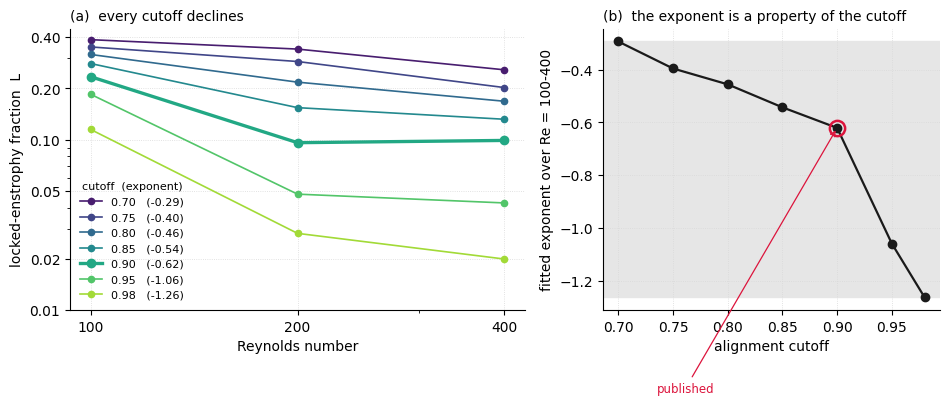

In [8]:
from matplotlib.ticker import NullFormatter
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 4.3), gridspec_kw={'width_ratios':[1.35, 1]})
cols = plt.cm.viridis(np.linspace(0.08, 0.86, len(ths)))
for th, c, e in zip(ths, cols, exps):
    L = [best[r][f"L{int(th*100)}"] for r in Res]
    a.plot(Res, L, 'o-', color=c, lw=2.4 if th==0.90 else 1.2, ms=6 if th==0.90 else 4.5,
           label=f"{th:.2f}   ({e:+.2f})", zorder=3 if th==0.90 else 2)
if not QUICK:
    a.plot([400], [max(runs[(64,400)], key=lambda d:d['ens'])['locked']], 's',
           ms=9, mfc='none', mec='crimson', mew=1.6, zorder=4)
    a.annotate("64$^3$ grid,\nsame physics", xy=(400, 0.0992), xytext=(180, 0.135),
               fontsize=8, color='crimson', arrowprops=dict(arrowstyle='-', lw=0.8, color='crimson'))
a.set_xscale('log'); a.set_yscale('log'); a.set_xticks(Res); a.set_xticklabels(['100','200','400'])
a.xaxis.set_minor_formatter(NullFormatter()); a.yaxis.set_minor_formatter(NullFormatter())
a.set_yticks([0.01,0.02,0.05,0.1,0.2,0.4]); a.set_yticklabels(['0.01','0.02','0.05','0.10','0.20','0.40'])
a.set_xlabel("Reynolds number"); a.set_ylabel("locked-enstrophy fraction  L")
a.set_title("(a)  every cutoff declines", fontsize=10, loc='left')
a.legend(title="cutoff  (exponent)", fontsize=8, title_fontsize=8, frameon=False, loc='lower left')
a.grid(True, ls=':', lw=0.6, color='0.85'); a.set_axisbelow(True)

b.plot(ths, exps, 'o-', color='#1a1a1a', lw=1.6, ms=6)
b.plot([0.90], [exps[ths.index(0.90)]], 'o', ms=11, mfc='none', mec='crimson', mew=1.8)
b.annotate("published", xy=(0.90, exps[ths.index(0.90)]), xytext=(0.735, -1.62), fontsize=8.5,
           color='crimson', arrowprops=dict(arrowstyle='->', lw=0.9, color='crimson'))
b.axhspan(min(exps), max(exps), color='0.9', zorder=0)
b.set_xlabel("alignment cutoff"); b.set_ylabel("fitted exponent over Re = 100-400")
b.set_title("(b)  the exponent is a property of the cutoff", fontsize=10, loc='left')
b.grid(True, ls=':', lw=0.6, color='0.85'); b.set_axisbelow(True)
for ax in (a, b):
    for s in ('top','right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

---
## 7. The fluid is pulled, not pushed — Table 6

Every native driving term in the momentum equation is a gradient: pressure enters as $-\nabla p$,
body forces as $-\nabla\Phi$, viscosity as diffusion. Advection transports but does not force. The
only push in the system is the external force $\mathbf{f}$ — which is exactly what Clay statements
(C) and (D) permit and (A) and (B) forbid.

For incompressible flow the pull is global and instantaneous: $\Delta p = -\rho\nabla\cdot(\mathbf{u}\cdot\nabla\mathbf{u})$
couples every point to every other at each instant. A compactly supported velocity blob
demonstrates it directly.

In [9]:
Np = 128; Lb = 2*np.pi
xp = np.linspace(0, Lb, Np, endpoint=False); X, Y, Z = np.meshgrid(xp, xp, xp, indexing='ij')
kk = np.fft.fftfreq(Np, 1.0/Np); KXp, KYp, KZp = np.meshgrid(kk, kk, kk, indexing='ij')
K2p = KXp**2 + KYp**2 + KZp**2; K2p[0,0,0] = 1
c = Lb/2; r2 = (X-c)**2 + (Y-c)**2 + (Z-c)**2; s = 0.3
psi = np.exp(-r2/(2*s**2))
up = np.gradient(psi, xp[1]-xp[0], axis=1); vp = -np.gradient(psi, xp[1]-xp[0], axis=0); wp = np.zeros_like(up)
dd = lambda f, ax: np.real(np.fft.ifftn(1j*[KXp,KYp,KZp][ax]*np.fft.fftn(f)))
rhs = -(dd(up,0)*dd(up,0) + dd(vp,0)*dd(up,1) + dd(wp,0)*dd(up,2)
      + dd(up,1)*dd(vp,0) + dd(vp,1)*dd(vp,1) + dd(wp,1)*dd(vp,2)
      + dd(up,2)*dd(wp,0) + dd(vp,2)*dd(wp,1) + dd(wp,2)*dd(wp,2))
pp = np.real(np.fft.ifftn(np.fft.fftn(rhs)/K2p))
rad = np.sqrt(r2); vel = np.sqrt(up**2 + vp**2 + wp**2)

print(f"  {'radius R':>10}{'max|u| beyond R':>20}{'max|p| beyond R':>20}   (fractions of each peak)")
for R in (0.5, 1.0, 1.5, 2.0, 2.5, 3.0):
    mm = rad > R
    print(f"  {R:>10.1f}{vel[mm].max()/vel.max():>20.2e}{np.abs(pp)[mm].max()/np.abs(pp).max():>20.2e}")
print("\n  At R = 3.0 the velocity is gone to 1 part in 10^20 and the pressure is still at 10^-3.")
print("  Nothing propagated. The far field is already being pulled.")

    radius R     max|u| beyond R     max|p| beyond R   (fractions of each peak)
         0.5            6.89e-01            2.37e-01
         1.0            2.19e-02            3.34e-02
         1.5            3.36e-05            9.82e-03
         2.0            2.87e-09            4.13e-03
         2.5            1.46e-14            2.22e-03
         3.0            4.65e-21            1.72e-03

  At R = 3.0 the velocity is gone to 1 part in 10^20 and the pressure is still at 10^-3.
  Nothing propagated. The far field is already being pulled.


---
## 8. What this establishes, and what it does not

**Established.** An independent engine reproduces the July 2026 measurements to three or four
significant figures. The globally averaged depletion ratio is quantitatively blind to locked
alignment — thirteen to fifteen times looser than the direct measurement. Over the resolved range
Re = 100–400 the locked fraction declines with Reynolds number at *every* cutoff tested, and the
near-aligned tail depletes about eight times faster than the moderately aligned bulk. At fixed
grid, resolution error in this diagnostic is the same size as the physical trend.

**Falsified within the paper.** The fitted exponent $\mathrm{Re}^{-1.24}$ is not a property of the
flow; it is a property of the cutoff, which moves it from $-0.46$ to $-1.95$.

**Retracted.** The February 2026 claim that positive viscosity guarantees global regularity.

**Not established, and not claimed.** Nothing here bears on global regularity. Two intervals of
Reynolds number, one flow, one initial condition, a periodic domain. No uniform bound. The
behaviour above Re = 400 is unknown, not favourable.

**Next runs.** Re = 800 at N ≈ 160 and Re = 1600 at N ≈ 256 to extend the resolved range; the full
enstrophy-weighted density of $|\cos(\boldsymbol\omega, e_1)|$ in place of any threshold; and
evaluation of these diagnostics on the September 2026 blowup construction, where the prediction is
that the core locks and the forcing term accounts for the excess of production over dissipation.

In [11]:
import numpy as np
from collections import deque

HEX = "0123456789abcdef"


def hex_vector(s: str) -> np.ndarray:
    """One-hot vector representation of a hex string."""
    s = s.lower().replace("0x", "")
    x = np.zeros((len(s), 16), dtype=np.float64)

    for i, ch in enumerate(s):
        x[i, HEX.index(ch)] = 1.0

    return x


def flatten(x: np.ndarray) -> np.ndarray:
    return x.reshape(-1)


def rotate(x: np.ndarray, k: int) -> np.ndarray:
    return np.roll(x, k, axis=0)


def reverse(x: np.ndarray) -> np.ndarray:
    return x[::-1]


def shift_scale(x: np.ndarray, k: int) -> np.ndarray:
    """
    A simple position/state transformation.
    This is an experimental operator, not yet a claimed physical law.
    """
    y = np.zeros_like(x)

    for i in range(len(x)):
        digit = np.argmax(x[i])
        j = (i + digit + 1) % len(x)
        y[j] = x[i]

    return y


TRANSFORMS = (
    lambda x: x,
    reverse,
    lambda x: rotate(x, 1),
    lambda x: rotate(x, -1),
    shift_scale,
)


def state_key(x: np.ndarray) -> bytes:
    return x.astype(np.uint8).tobytes()


def closure(x0: np.ndarray, depth: int = 4):
    seen = {state_key(x0)}
    states = {state_key(x0): x0.copy()}
    frontier = [x0]

    for _ in range(depth):
        new_frontier = []

        for x in frontier:
            for T in TRANSFORMS:
                y = T(x)
                k = state_key(y)

                if k not in seen:
                    seen.add(k)
                    states[k] = y
                    new_frontier.append(y)

        frontier = new_frontier

    return list(states.values())